<a href="https://colab.research.google.com/github/192231/Metodos-Num-ricos-I/blob/main/MetododeNR.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#**Método de Newton-Raphson**

En este método, tomamos una aproximación inicial $p_0$ y usamos la ecuación iterativa

$P_n= p_{n-1}-\frac {f(p_{n-1})} {f'(p_{n-1})}$&emsp;&emsp; con &emsp;&emsp; $n≥1$

Para hallar aproximadamente la raíz $p$ de la ecuación $f(x)=0$, requerimos que cada $f'(x)≠0$ en cada $P_n$

Queremos resolver la ecuación $f(x)=cos(x)-x=0$ en el intervalo $[0,\frac{π}{2}]$ y con $p_0=\frac{π}{4}≈0.7853981634$

Nosotros generamos la sucesión mediante:  
$P_n= p_{n-1}-\frac{cos(p_n-1)-p_{n-1}}{-sen(p_{n-1})-1}$

Hagamos la primer iteración:    
$P_1=\frac{π}{4}-\frac{cos(\frac{π}{4})-\frac{π}{4}}{-sen(\frac{π}{4})-1}= 0.73953613352$

Sigamos con del código para ahorrarnos hacer las demás iteraciones

Importamos la librería numpy, que tiene funciones matemáticas, matplotlib que permite gráficas y pandas para estructurar datos.

In [26]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

Definimos la función $f(x)$

In [27]:
def f(x):
    return np.cos(x)-x

*Graficamos la función*

Text(1, 0.6, '$y = \\cos x$')

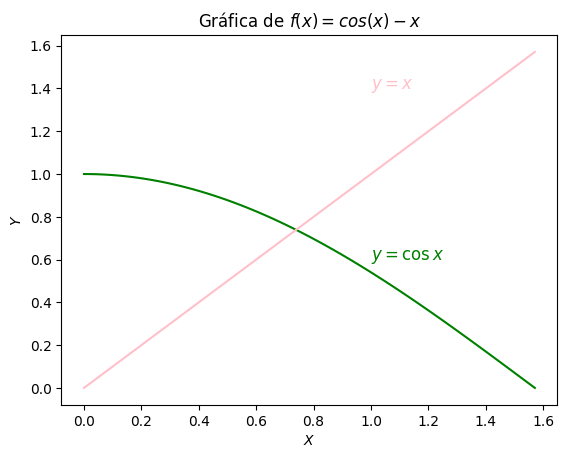

In [52]:
xx=np.linspace(0,np.pi/2,100)
plt.plot(xx,np.cos(xx),label='y=cosx',color='green')
plt.plot(xx,xx,label='y=x',color='pink')
plt.title("Gráfica de $f(x)=cos(x)-x$")
plt.xlabel("$X$")
plt.ylabel("$Y$")
plt.text(1,1.4,'$y=x$',fontsize=12,color='pink')
plt.text(1,0.6, r'$y = \cos x$',fontsize=12,color='green')

Estos son los parametros y los criterios:

In [34]:
def newton(p0,tol):
  error=100
  Lerror=[]
  Lp_i=[p0]
  while error>tol:
    p1=p0-(np.cos(p0)-p0)/(-np.sin(p0)-1)
    error=np.abs(p1-p0)
    Lerror.append(error)
    Lp_i.append(p1)
    p0=p1
  return Lp_i, Lerror


In [62]:
lista_p,lista_errores=newton(np.pi/4,0.00000001)
pnmenosuno=lista_p[:-1]
pn=lista_p[1:]
df=pd.DataFrame({'P_n-1':pnmenosuno, 'P_n':pn,'Error=|P_n - P_n-1|':lista_errores})
df.index=range(1,len(df)+1)
df.index.name='n'
pd.set_option('display.precision',10)
df=df.fillna('-')
df

,P_n-1,P_n,Error=|P_n - P_n-1|
n,,,
1,0.7853981634,0.7395361335,4.5862029882e-02
2,0.7395361335,0.7390851781,4.5095540923e-04
3,0.7390851781,0.7390851332,4.4890849038e-08
4,0.7390851332,0.7390851332,4.4408920985e-16


Con este ejemplo nos podemos dar cuenta que el **Método de Newton-Rapshon** puede dar aproximaciones en extremo precisas con muy pocas iteraciones, por lo que es muy **eficaz**.